In [29]:
# Konfiguracja wyglądu punktów na wykresach
POINT_STYLES = {
    "stations": {"color": "#80C4E9", "size": 30, "alpha": 0.5},
    "binned": {"color": "#102A43", "size": 50, "alpha": 0.7},
    "excluded": {"facecolor": "white", "edgecolor": "#102A43", "size": 50, "alpha": 0.7},
}

from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gmean

def _apply_project_plot_style():
    current = Path.cwd()
    for path in [current, *current.parents]:
        if (path / "plot_style.py").is_file():
            if str(path) not in sys.path:
                sys.path.insert(0, str(path))

            import plot_style

            plot_style.apply_montserrat_style()
            return

_apply_project_plot_style()

In [30]:
def find_project_root(start=None):
    current = Path.cwd() if start is None else Path(start)
    for path in [current, *current.parents]:
        if (path / "Data").exists():
            return path
    raise FileNotFoundError("Could not find project root containing Data/")


PROJECT_ROOT = find_project_root()
BASE_DIR = PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "Data"
DATA_FILE = DATA_DIR / "rides_data_without_discontinuities.parquet"

rides_data = pd.read_parquet(DATA_FILE, columns=[
    "start_station_id", "start_station_name", "start_date", "start_day_of_week"
])

In [31]:
def log_binning_my(mean, variance, a):
    # Funkcję opracował Artur Werys

    # Konwersja danych na tablice NumPy
    mean = np.asarray(mean)
    variance = np.asarray(variance)

    mean_min = min(mean)
    mean_max = max(mean)

    # Generowanie granic przedziałów logarytmicznych
    granice = [mean_min]

    while granice[-1] <= mean_max:
        granice.append(granice[-1] * a)

    # Listy punktów reprezentacyjnych
    srednie_reprezentacyjne = []
    wariancje_reprezentacyjne = []

    # Obliczanie średnich geometrycznych dla kolejnych przedziałów
    for i in range(len(granice) - 1):

        lewy_kraniec = granice[i]
        prawy_kraniec = granice[i + 1]

        # Wybór stacji należących do danego przedziału
        maska = (mean >= lewy_kraniec) & (mean < prawy_kraniec)

        srednie_w_przedziale = mean[maska]
        wariancje_w_przedziale = variance[maska]

        # Pominięcie pustych przedziałów
        if len(srednie_w_przedziale) == 0:
            continue

        # Średnie geometryczne dla stacji w danym przedziale
        srednia_geo = gmean(srednie_w_przedziale)
        wariancja_geo = gmean(wariancje_w_przedziale)

        srednie_reprezentacyjne.append(srednia_geo)
        wariancje_reprezentacyjne.append(wariancja_geo)

    return srednie_reprezentacyjne, wariancje_reprezentacyjne

In [32]:
may_2024 = rides_data[
    (rides_data["start_date"].dt.year == 2024) &
    (rides_data["start_date"].dt.month == 5)
]

# Zamiana kolumny "start_date" na typ daty bez czasu
may_2024["start_date"] = may_2024["start_date"].dt.date

may_2024.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
166,1199,"The Tennis Courts, The Regent's Park",2024-05-01,Wednesday
167,2691,"Howland Street, Fitzrovia",2024-05-01,Wednesday
168,1194,"Westminster University, Marylebone",2024-05-01,Wednesday
169,1091,"St. John's Wood Church, The Regent's Park",2024-05-02,Thursday
170,1153,"Pall Mall East, West End",2024-05-02,Thursday
...,...,...,...,...
14905575,200012,"Stepney Green Station, Stepney",2024-05-30,Thursday
14905576,300056,"Mile End Stadium, Mile End",2024-05-31,Friday
14905577,1153,"Pall Mall East, West End",2024-05-31,Friday
15202763,300207,"Gauden Road, Clapham",2024-05-30,Thursday


In [33]:
# Czy stacja była aktywna przez cały miesiąc?

station_activity = (
    may_2024
    .groupby("start_station_id")["start_date"]
    .agg(days_with_rides="nunique")
)

station_activity.head(-5)

,days_with_rides
start_station_id,
959,31
960,31
961,31
962,31
963,31
...,...
300242,31
300243,31
300244,31


In [34]:
# Wybieramy tylko stacje, które były aktywne przez cały miesiąc

valid_stations = station_activity[station_activity["days_with_rides"] == 31].index
may_2024_filtered = may_2024[may_2024["start_station_id"].isin(valid_stations)]
may_2024_filtered.head(-5)

,start_station_id,start_station_name,start_date,start_day_of_week
166,1199,"The Tennis Courts, The Regent's Park",2024-05-01,Wednesday
167,2691,"Howland Street, Fitzrovia",2024-05-01,Wednesday
168,1194,"Westminster University, Marylebone",2024-05-01,Wednesday
169,1091,"St. John's Wood Church, The Regent's Park",2024-05-02,Thursday
170,1153,"Pall Mall East, West End",2024-05-02,Thursday
...,...,...,...,...
14905575,200012,"Stepney Green Station, Stepney",2024-05-30,Thursday
14905576,300056,"Mile End Stadium, Mile End",2024-05-31,Friday
14905577,1153,"Pall Mall East, West End",2024-05-31,Friday
15202763,300207,"Gauden Road, Clapham",2024-05-30,Thursday


In [35]:
# Policzenie ile było przejazdów dla każdej stacji dzień po dniu
daily_rides_per_station = (
    may_2024_filtered
    .groupby(["start_station_id", "start_date"])
    .size()
    .unstack()
)

In [36]:
daily_rides_per_station.head(2)

start_date,2024-05-01,2024-05-02,2024-05-03,2024-05-04,2024-05-05,2024-05-06,2024-05-07,2024-05-08,2024-05-09,2024-05-10,...,2024-05-22,2024-05-23,2024-05-24,2024-05-25,2024-05-26,2024-05-27,2024-05-28,2024-05-29,2024-05-30,2024-05-31
start_station_id,,,,,,,,,,,,,,,,,,,,,
959,51,46,15,19,17,8,26,42,41,45,...,19,32,28,27,22,18,33,30,28,16
960,98,95,68,88,102,38,100,125,163,140,...,51,105,120,137,62,76,93,86,103,85


In [37]:
# Średnia i wariancja dla każdej stacji

mean_and_variance_counts = pd.DataFrame({
    "mean_count": daily_rides_per_station.mean(axis=1),
    "variance": daily_rides_per_station.var(axis=1, ddof=0)
}).reset_index()

mean_and_variance_counts.head()

,start_station_id,mean_count,variance
0,959,27.612903,99.011446
1,960,99.032258,700.224766
2,961,25.806452,89.768991
3,962,24.419355,64.049948
4,963,34.193548,95.639958


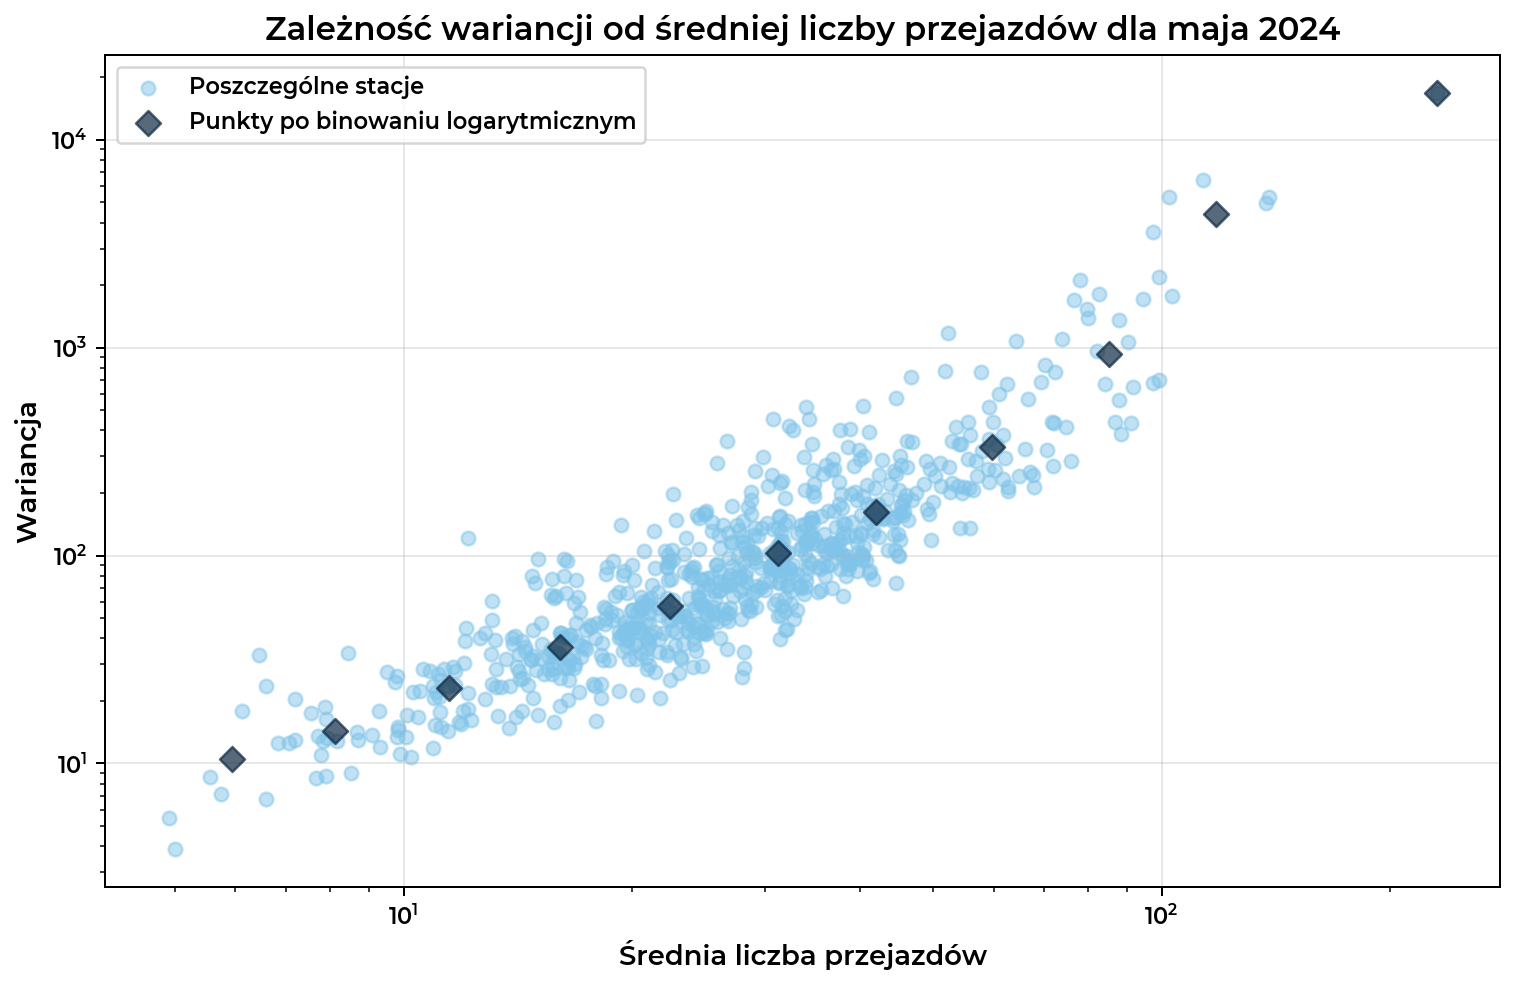

In [38]:
# Logarytmiczne przedziały
mean_log, variance_log = log_binning_my(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów
plt.scatter(
    mean_and_variance_counts["mean_count"], 
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu logarytmicznym
plt.scatter(
    mean_log, 
    variance_log,
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia liczba przejazdów")
plt.ylabel("Wariancja")
plt.title("Zależność wariancji od średniej liczby przejazdów dla maja 2024")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

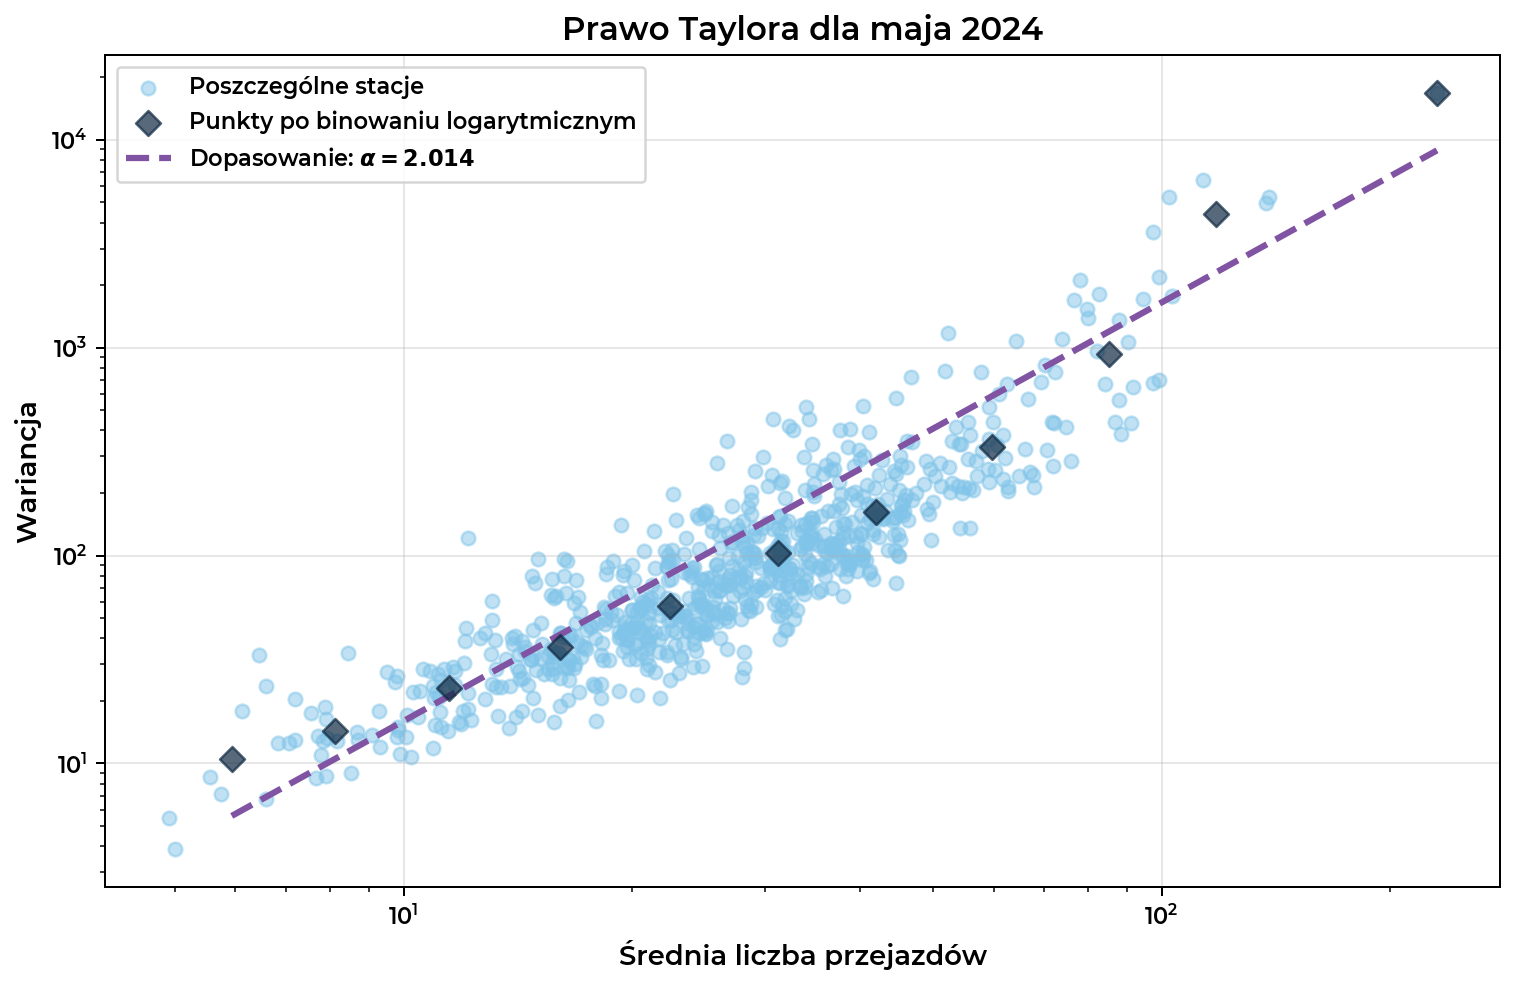

In [39]:
# Logarytmiczne przedziały
mean_log, variance_log = log_binning_my(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Dopasowanie linii regresji do punktów po binowaniu logarytmicznym
x = np.log(mean_log)
y = np.log(variance_log)

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Dopasowana prosta - generowanie punktów do wykresu
x_fit = np.geomspace(min(mean_log), max(mean_log), 100)
y_fit = A * x_fit ** alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów
plt.scatter(
    mean_and_variance_counts["mean_count"], 
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu logarytmicznym
plt.scatter(
    mean_log, 
    variance_log,
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color="#8054A3",
    linestyle="--",
    linewidth=2.5,
    zorder=2,
    label=fr"Dopasowanie: $\alpha = {alpha:.3f}$"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Średnia liczba przejazdów")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2024")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

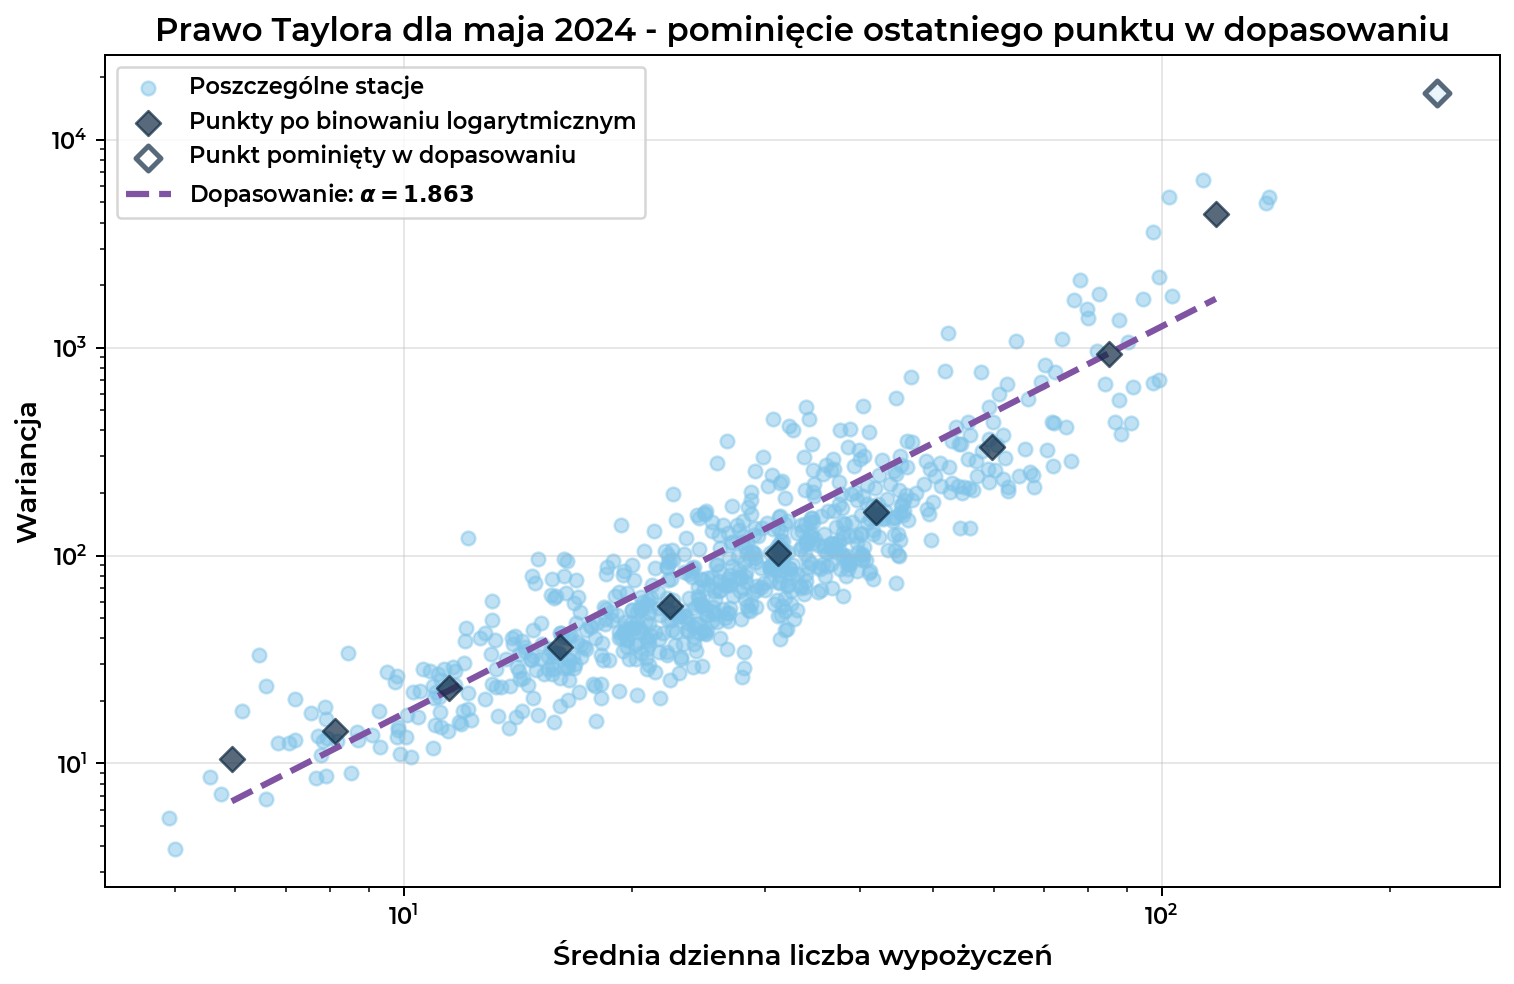

alpha = 1.8628
A = 0.2382


In [40]:
# Binowanie logarytmiczne
mean_log, variance_log = log_binning_my(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    a=1.4
)

# Dopasowanie prawa Taylora z pominięciem ostatniego punktu
x = np.log(mean_log[:-1])
y = np.log(variance_log[:-1])

alpha, log_A = np.polyfit(x, y, 1)
A = np.exp(log_A)

# Generowanie punktów dopasowanej funkcji
x_fit = np.geomspace(min(mean_log[:-1]), max(mean_log[:-1]), 100)
y_fit = A * x_fit**alpha

# Wykres
plt.figure(figsize=(10, 6))

# Chmura punktów – poszczególne stacje
plt.scatter(
    mean_and_variance_counts["mean_count"],
    mean_and_variance_counts["variance"],
    color=POINT_STYLES["stations"]["color"],
    alpha=POINT_STYLES["stations"]["alpha"],
    s=POINT_STYLES["stations"]["size"],
    zorder=1,
    label="Poszczególne stacje"
)

# Punkty po binowaniu uwzględnione w dopasowaniu
plt.scatter(
    mean_log[:-1],
    variance_log[:-1],
    color=POINT_STYLES["binned"]["color"],
    alpha=POINT_STYLES["binned"]["alpha"],
    marker="D",
    s=POINT_STYLES["binned"]["size"],
    zorder=3,
    label="Punkty po binowaniu logarytmicznym"
)

# Ostatni punkt pominięty w dopasowaniu
plt.scatter(
    mean_log[-1],
    variance_log[-1],
    marker="D",
    facecolors=POINT_STYLES["excluded"]["facecolor"],
    edgecolors=POINT_STYLES["excluded"]["edgecolor"],
    alpha=POINT_STYLES["excluded"]["alpha"],
    linewidths=2,
    s=POINT_STYLES["excluded"]["size"],
    zorder=3,
    label="Punkt pominięty w dopasowaniu"
)

# Dopasowana funkcja potęgowa
plt.plot(
    x_fit,
    y_fit,
    color="#8054A3",
    linestyle="--",
    linewidth=2.5,
    zorder=2,
    label=fr"Dopasowanie: $\alpha = {alpha:.3f}$"
)

# Skala logarytmiczna
plt.xscale("log")
plt.yscale("log")

# Opisy wykresu
plt.xlabel("Średnia dzienna liczba wypożyczeń")
plt.ylabel("Wariancja")
plt.title("Prawo Taylora dla maja 2024 - pominięcie ostatniego punktu w dopasowaniu")

plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Parametry dopasowania
print(f"alpha = {alpha:.4f}")
print(f"A = {A:.4f}")

In [41]:
import openmeteo_requests

import pandas as pd
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = 3600)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
url = "https://api.open-meteo.com/v1/forecast"
params = {
	"latitude": 52.52,
	"longitude": 13.41,
	"hourly": "temperature_2m",
}
responses = openmeteo.weather_api(url, params = params)

# Process first location. Add a for-loop for multiple locations or weather models
response = responses[0]
print(f"Coordinates: {response.Latitude()}°N {response.Longitude()}°E")
print(f"Elevation: {response.Elevation()} m asl")
print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

# Process hourly data. The order of variables needs to be the same as requested.
hourly = response.Hourly()
hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()

hourly_data = {
	"date": pd.date_range(
		start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
		end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
		freq = pd.Timedelta(seconds = hourly.Interval()),
		inclusive = "left"
	)
}

hourly_data["temperature_2m"] = hourly_temperature_2m

hourly_dataframe = pd.DataFrame(data = hourly_data)
print("\nHourly data\n", hourly_dataframe)


Coordinates: 52.512603759765625°N 13.419516563415527°E
Elevation: 38.0 m asl
Timezone difference to GMT+0: 0s

Hourly data
                          date  temperature_2m
0   2026-10-31 00:00:00+00:00        8.545500
1   2026-10-31 01:00:00+00:00        8.545500
2   2026-10-31 02:00:00+00:00        8.595500
3   2026-10-31 03:00:00+00:00        8.745500
4   2026-10-31 04:00:00+00:00        8.945499
..                        ...             ...
163 2026-11-06 19:00:00+00:00        4.045500
164 2026-11-06 20:00:00+00:00        3.945500
165 2026-11-06 21:00:00+00:00        3.895500
166 2026-11-06 22:00:00+00:00        3.995500
167 2026-11-06 23:00:00+00:00        4.245500

[168 rows x 2 columns]
